In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

/private/tmp/claude-501/-Users-caglartunc/4c668e71-68ad-4904-9e51-5e6a5282eec4/scratchpad/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Data loading

In [2]:
train_df = pd.read_csv("Train.csv")

# Split inputs and targets
train_inputs = train_df.drop(columns=['target'])
train_targets = train_df['target']

# Select features
dropped_columns = ['device', 'id']
train_inputs = train_inputs.drop(columns=dropped_columns)

# Split BEFORE any preprocessing, so nothing learned from the test rows
# (medians, categories, ...) can leak into training.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(train_inputs, train_targets, test_size = 0.2, random_state = 0)

# Preprocessing (fitted on the training split only)

Changes with respect to the original notebook:

* **Missingness indicators.** About 45–61% of the secondary-cell (`SCell_*`) values are missing, mostly because there was no secondary cell at all. Filling them with 0 makes "no secondary cell" indistinguishable from an actual measurement of 0, so we add an explicit `missingindicator_<feature>` column for each `SCell_*` feature.
* **Imputation.** Zero imputation is compared with median imputation. The median is computed on the training split only.
* **`area` is categorical, not ordinal.** `OrdinalEncoder` would impose an arbitrary order on Avenue/Park/Residential/Highway/Tunnel, so we one-hot encode it instead.

In [3]:
categorical_features = ['area']
numeric_features = [c for c in X_train_raw.columns if c not in categorical_features]
scell_features = [c for c in numeric_features if c.startswith('SCell_')]

def make_preprocessor(impute_strategy, add_indicators=True):
    if impute_strategy == 'zero':
        imputer = SimpleImputer(strategy='constant', fill_value=0)
    else:
        imputer = SimpleImputer(strategy=impute_strategy)
    transformers = [('num', imputer, numeric_features)]
    if add_indicators:
        transformers.append(('missing', MissingIndicator(features='all'), scell_features))
    transformers.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features))
    return ColumnTransformer(transformers, verbose_feature_names_out=False).set_output(transform='pandas')

def evaluate(model, X, y):
    pred = model.predict(X)
    # target is in bit/s; report errors in Mbit/s for readability
    return {'MAE [Mbit/s]': mean_absolute_error(y, pred) / 1e6,
            'RMSE [Mbit/s]': np.sqrt(mean_squared_error(y, pred)) / 1e6,
            'R2': r2_score(y, pred)}

# Model evaluation on the held-out test set

The preprocessing and XGBoost are fitted on `X_train_raw` only and evaluated on `X_test_raw`. Zero and median imputation are compared, each with and without the missingness indicators.

In [4]:
results = {}
for impute_strategy in ['zero', 'median']:
    for add_indicators in [False, True]:
        prep = make_preprocessor(impute_strategy, add_indicators)
        Xtr = prep.fit_transform(X_train_raw).astype(float)
        Xte = prep.transform(X_test_raw).astype(float)
        model = xgboost.XGBRegressor(n_estimators=100, max_depth=2).fit(Xtr, y_train)
        results[(impute_strategy, add_indicators)] = {
            **{'train ' + k: v for k, v in evaluate(model, Xtr, y_train).items()},
            **{'test ' + k: v for k, v in evaluate(model, Xte, y_test).items()},
        }

results = pd.DataFrame(results).T
results.index.names = ['imputation', 'missing indicators']
results.round(3)

train MAE [Mbit/s]  train RMSE [Mbit/s]  \
imputation missing indicators                                            
zero       False                            8.006               12.142   
           True                             8.006               12.142   
median     False                            8.202               12.318   
           True                             8.125               12.193   

                               train R2  test MAE [Mbit/s]  \
imputation missing indicators                                
zero       False                  0.921              8.066   
           True                   0.921              8.066   
median     False                  0.919              8.247   
           True                   0.920              8.239   

                               test RMSE [Mbit/s]  test R2  
imputation missing indicators                               
zero       False                           12.103    0.922  
           True                            12.103    0.922  
median     False                           12.327    0.919  
           True                            12.266    0.920

# Final model

For the explanations below we use **median imputation + missingness indicators + one-hot `area`**. The configuration is chosen on principle rather than by picking the best test score, since choosing it by test score would turn the test set into a validation set. All explanations are computed on the **test** split.

In [5]:
preprocessor = make_preprocessor('median', add_indicators=True)
X_train = preprocessor.fit_transform(X_train_raw).astype(float)
X_test = preprocessor.transform(X_test_raw).astype(float)

model_xgb = xgboost.XGBRegressor(n_estimators=100, max_depth=2).fit(X_train, y_train)
pd.DataFrame({'train': evaluate(model_xgb, X_train, y_train),
              'test': evaluate(model_xgb, X_test, y_test)}).round(3)

,train,test
MAE [Mbit/s],8.125,8.239
RMSE [Mbit/s],12.193,12.266
R2,0.920,0.920


# SHAP explanations

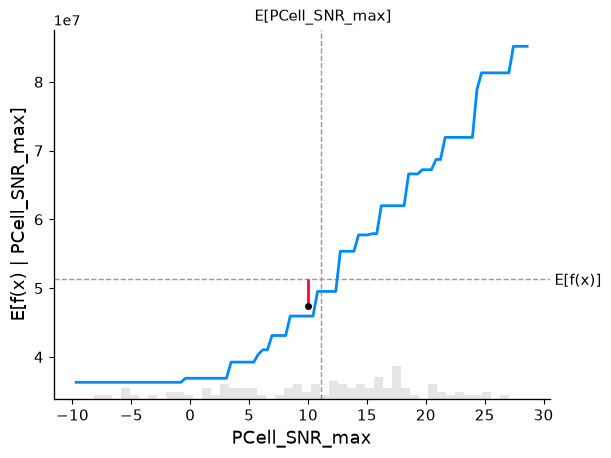

In [6]:
# background sample from the training split, explanations on the test split
X100 = shap.utils.sample(X_train, 100)

# explain the XGBoost model with SHAP
explainer_xgb = shap.Explainer(model_xgb, X100)
shap_values_xgb = explainer_xgb(X_test)

sample_ind = 2

# make a standard partial dependence plot with a single SHAP value overlaid
fig, ax = shap.partial_dependence_plot(
    "PCell_SNR_max",
    model_xgb.predict,
    X100,
    model_expected_value=True,
    feature_expected_value=True,
    show=False,
    ice=False,
    shap_values=shap_values_xgb[sample_ind : sample_ind + 1, :],
)


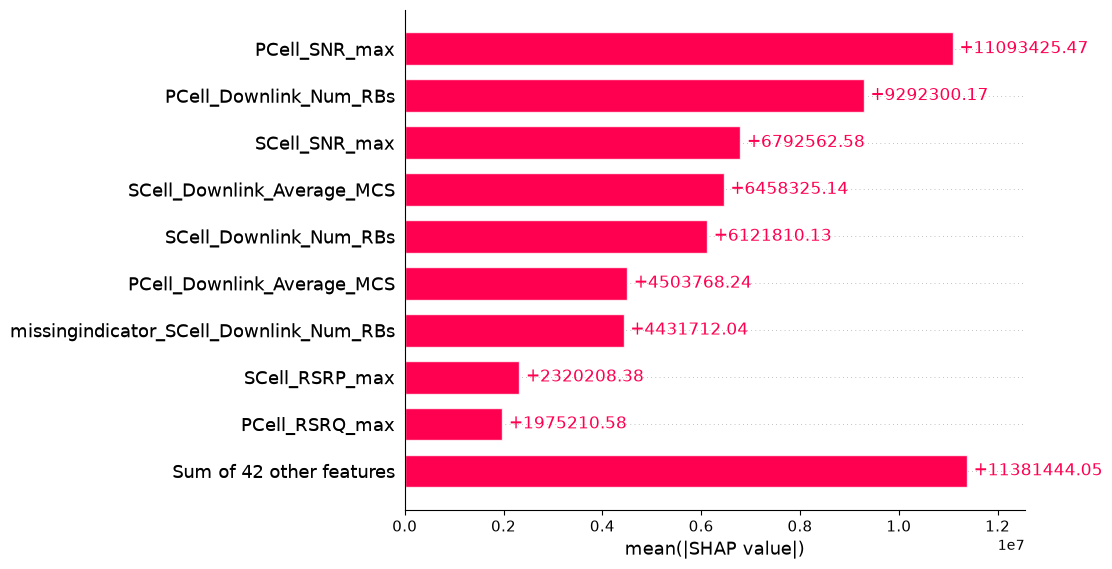

In [7]:
shap.plots.bar(shap_values_xgb)

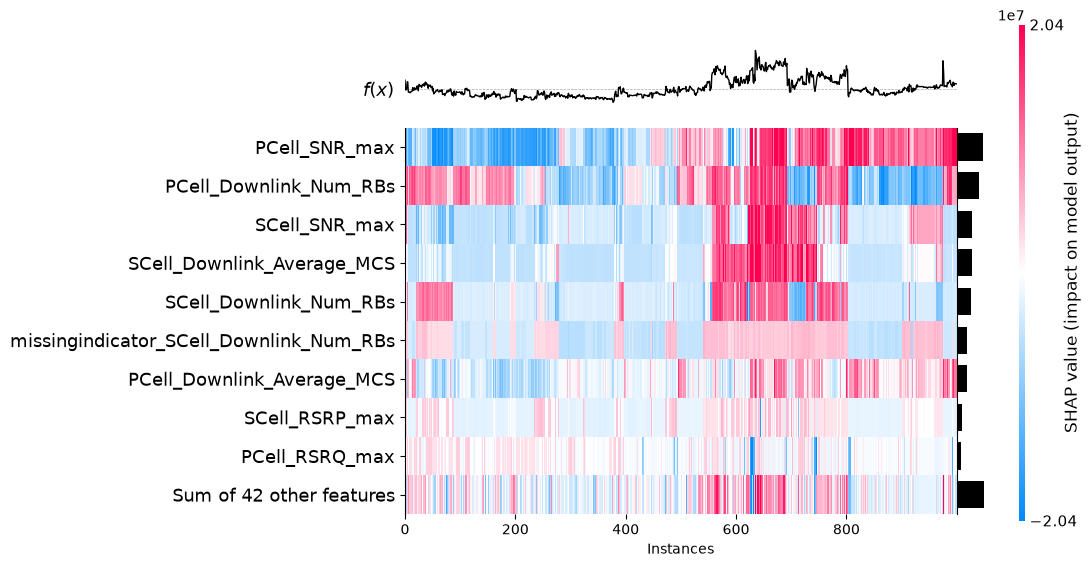

<Axes: xlabel='Instances'>

In [8]:
shap.plots.heatmap(shap_values_xgb[:1000])


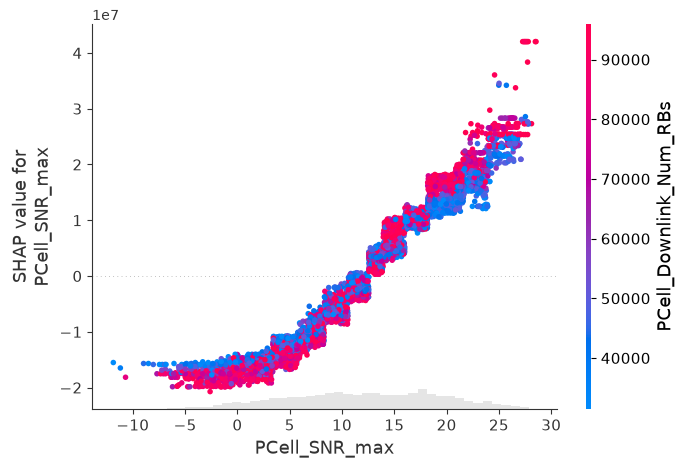

In [9]:
shap.plots.scatter(shap_values_xgb[:, "PCell_SNR_max"], color=shap_values_xgb)


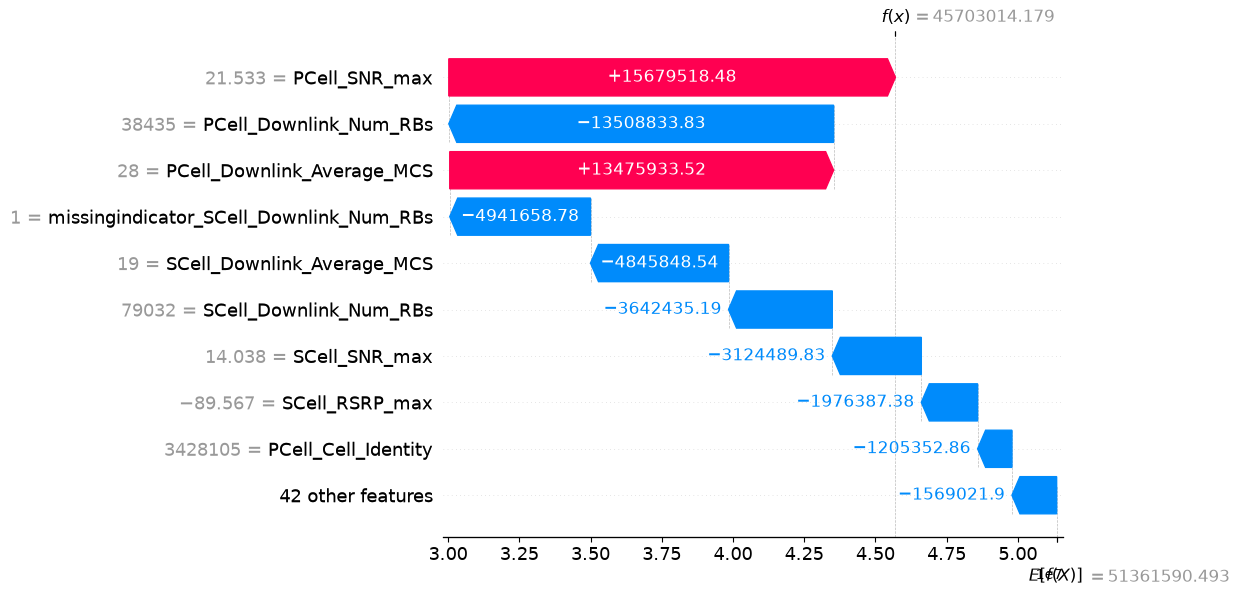

In [10]:
shap.plots.waterfall(shap_values_xgb[0])


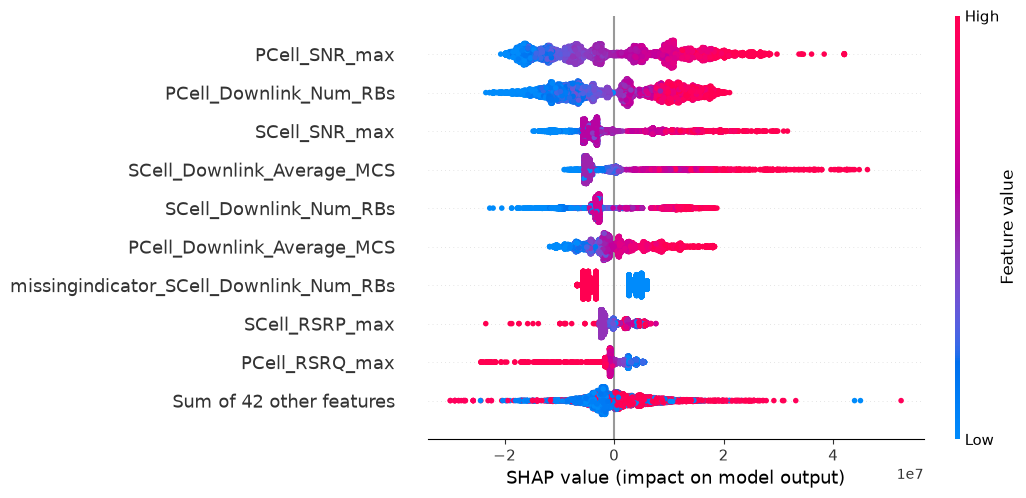

In [11]:
shap.plots.beeswarm(shap_values_xgb)

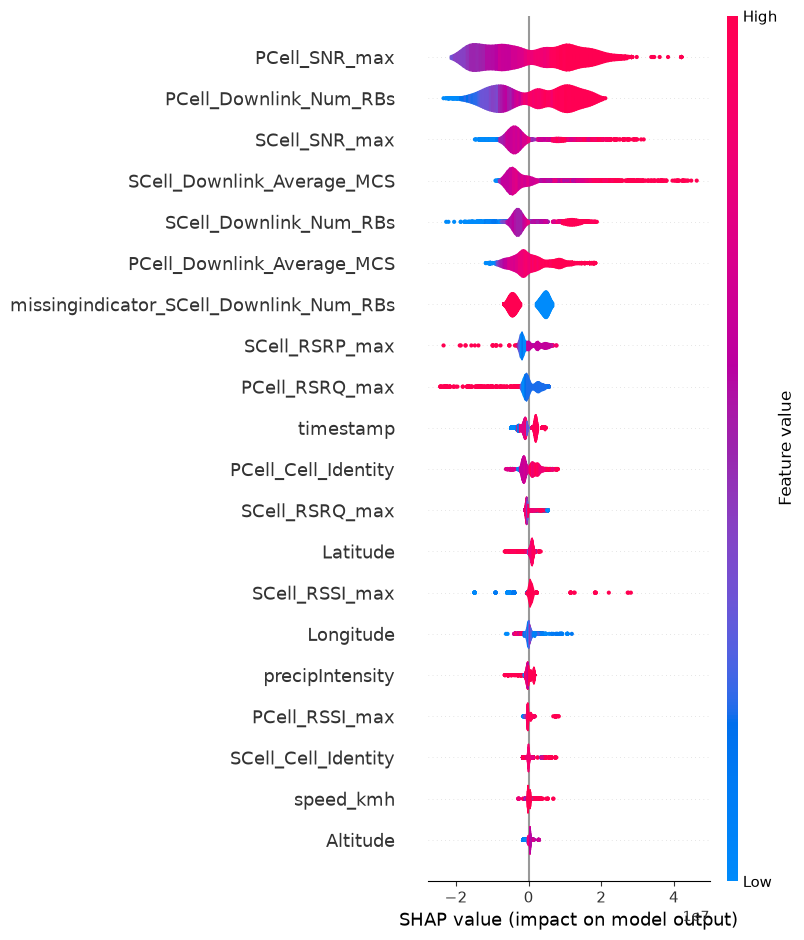

In [12]:
shap.summary_plot(shap_values_xgb, plot_type='violin')


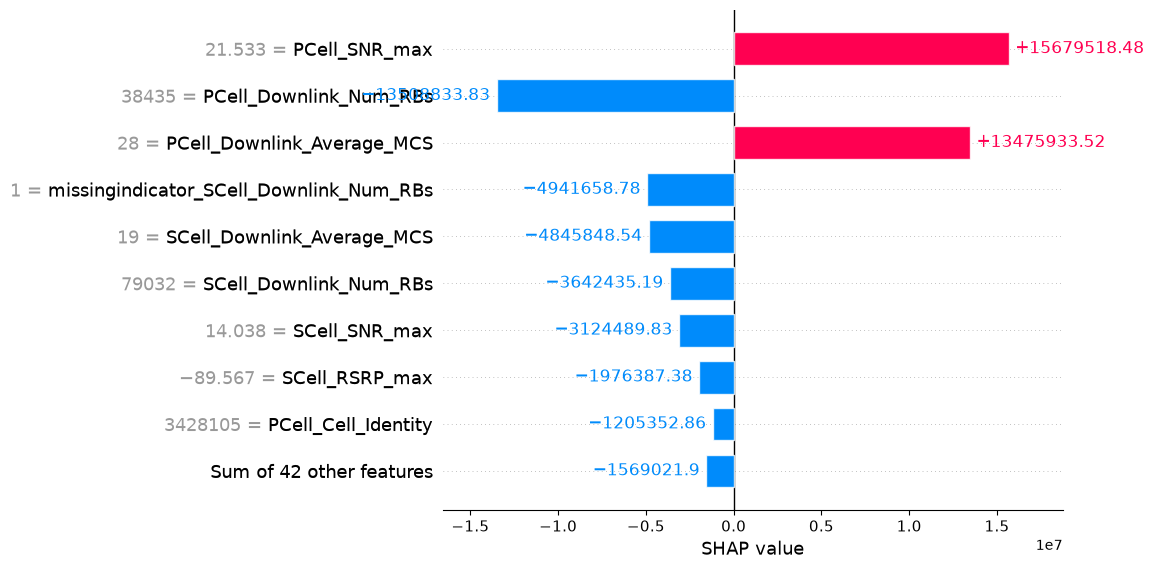

In [13]:
shap.plots.bar(shap_values_xgb[0])

In [14]:
shap.initjs()
shap.plots.force(shap_values_xgb[0], show=False,matplotlib=True )
plt.savefig('scratch.png')

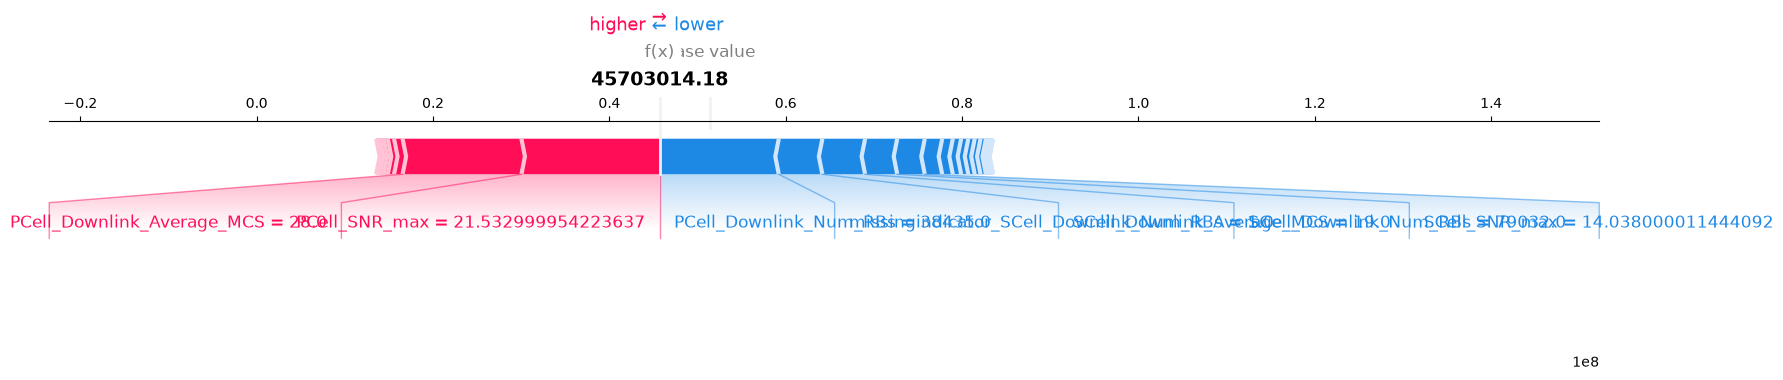

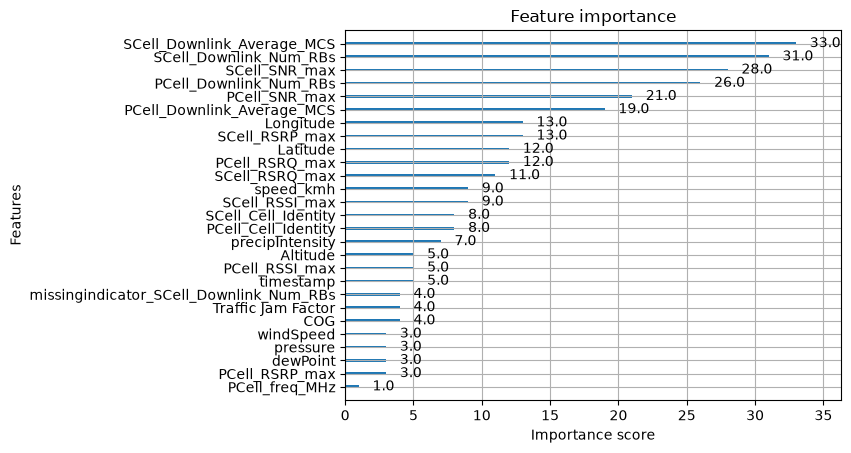

In [15]:
from xgboost import plot_importance
plot_importance(model_xgb)
plt.show()